# Estimador


Dado el vector de datos ${\bf x}_k \in R^{2\times 1}$ y matriz de transición $F_k$ relacionadas de la siguiente manera:

$$ {\bf x}_k =  F_k  {\bf x}_{k-1} +   {\bf w}_{k-1}  $$

siendo ${\bf w}_{k}\sim \mathcal{N}({\bf 0}, \sigma^2_w I_2) $ y  ${\bf w}_{k} \in R^{2\times 1}$ el vector que representa ruido en el sistema.

Además, las observaciones están dadas por:

$${\bf z}_k = H_k {\bf x}_k  + {\bf v}_k  $$


\begin{equation}
F_{k}=\left[\begin{array}{cc}
1 & \Delta t\\
0 & 1
\end{array}\right]
\end{equation}
\begin{equation}
G_{k}=\left[\begin{array}{c}
\frac{1}{2}\Delta t^{2}\\
\Delta t
\end{array}\right]
\end{equation}
\begin{equation}
H_{k}=\left[\begin{array}{cc}
1 & 0\end{array}\right]
\end{equation}



In [81]:
import numpy as np
import matplotlib.pyplot as plt


In [82]:
# Generación de N=1000 muestras de la señal x(n)
N=100
Ts = 0.1 # delta_t
t = Ts*np.arange(N)
x = np.zeros((2, N))
z = np.zeros((1, N))
S2_w = 1*np.eye(2) 
S2_v = 1

F = np.array([[1, Ts],[0, 1]])
H = np.array([[1, 0]])

for k in range(1, N):
  wk = np.linalg.cholesky(S2_w)@np.random.randn(2,1)
  xk_1 = np.reshape(x[:,k-1], (2,1))
  xk=F@xk_1 + wk
  x[:,k] = xk.ravel()

  vk = np.sqrt(S2_v)*np.random.randn(1)
  z[0, k] = H@xk + vk

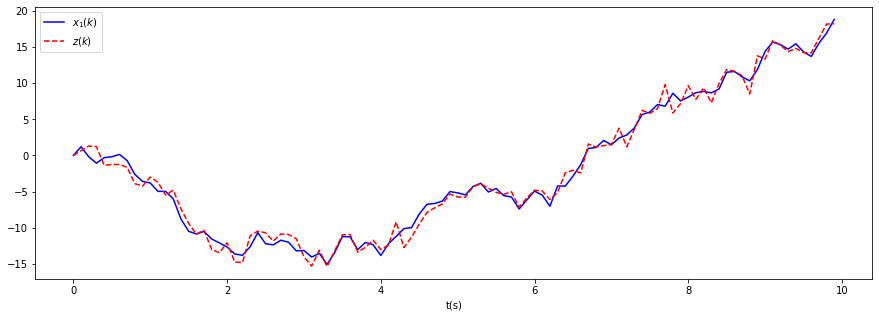

In [83]:
plt.figure(figsize=(15, 5))
plt.plot(t, x[0, :],'b-' , label = '$x_1(k)$')
plt.plot(t, z[0, :],'r--' , label = '$z(k)$')
plt.xlabel('t(s)')
plt.legend()

## Implementación del algoritmo LMS

In [84]:
def get_x_kalman(z,F,  H, P,  B=0, u = 0, Q=0, R=0):
  Dz, N = z.shape
  D = F.shape[1]
  N = z.shape[1]
  x_est = np.zeros((D, N))
  #
  FT = np.transpose(F)
  HT = np.transpose(H)
  #initial conditions
  x_k1_k1 = np.zeros((D,1))   #x_{k-1|k-1}

  for k in range(1, N):
    # prior estimations
    xk_k1 = F@x_k1_k1 + B*u   #x_{k|k-1}
    P  = F@P@FT + Q           #P_{k|k-1}
    zk = np.reshape(z[:, k], (Dz,1))
    yk = zk - H@xk_k1
    Sk = H@P@HT + R
    # Kalman Gain
    K = P@HT@np.linalg.inv(Sk )
    
    # Porsterior
    xk  = xk_k1 + K@yk
    P  = (np.eye(D) - K@H)@P
    yk = zk - H@xk
    x_k1_k1 = xk
    #save results
    x_est[:,k] = xk.ravel()
  return x_est


In [85]:
x_est = get_x_kalman(z,F,  H, P=np.eye(2), Q = S2_w, R = S2_v )

(8.0, 9.0, 60.0, 80.0)

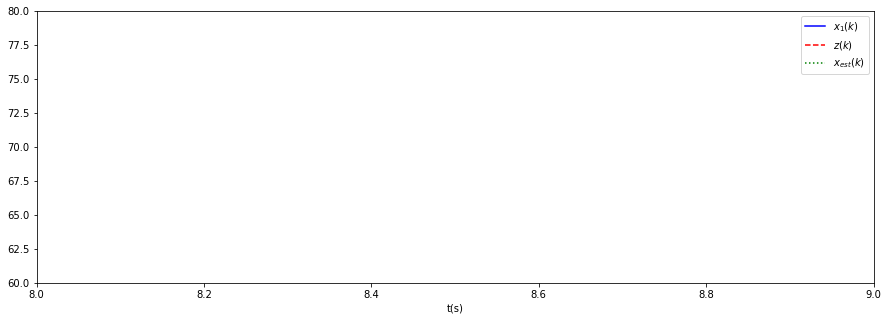

In [86]:
plt.figure(figsize=(15, 5))
plt.plot(t, x[0, :],'b-' , label = '$x_1(k)$')
plt.plot(t, z[0, :],'r--' , label = '$z(k)$')
plt.plot(t, x_est[0, :],'g:' , label = '$x_{est}(k)$')
plt.xlabel('t(s)')
plt.legend()
#plt.axis([0, 2, -5, 5])
plt.axis([8, 9, 60, 80])